<a href="https://colab.research.google.com/github/kelvincleophace0309/COU07506-labs/blob/main/COU07506_Week02_240141484517.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 DSP, Week 02: Lab 1A (Sampling, Aliasing and Quantization)
Name: Kelvin K Cleophace
Registration No.: 240141484517
Class: BENG24COE-1   Date: 25/11/2026

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

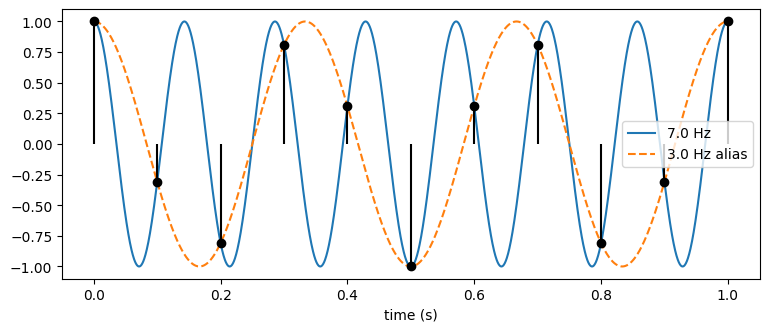

alias frequency = 3.0 Hz


In [ ]:
f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)          # dense grid = "analog" signal
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = abs(f0 - fs*round(f0/fs))
plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
plt.xlabel("time (s)"); plt.legend(); plt.show()
print("alias frequency =", f_alias, "Hz")

fs (Hz) | alias (Hz)
     10 | 3.0
     12 | 5.0
     14 | 7.0
     20 | 7.0


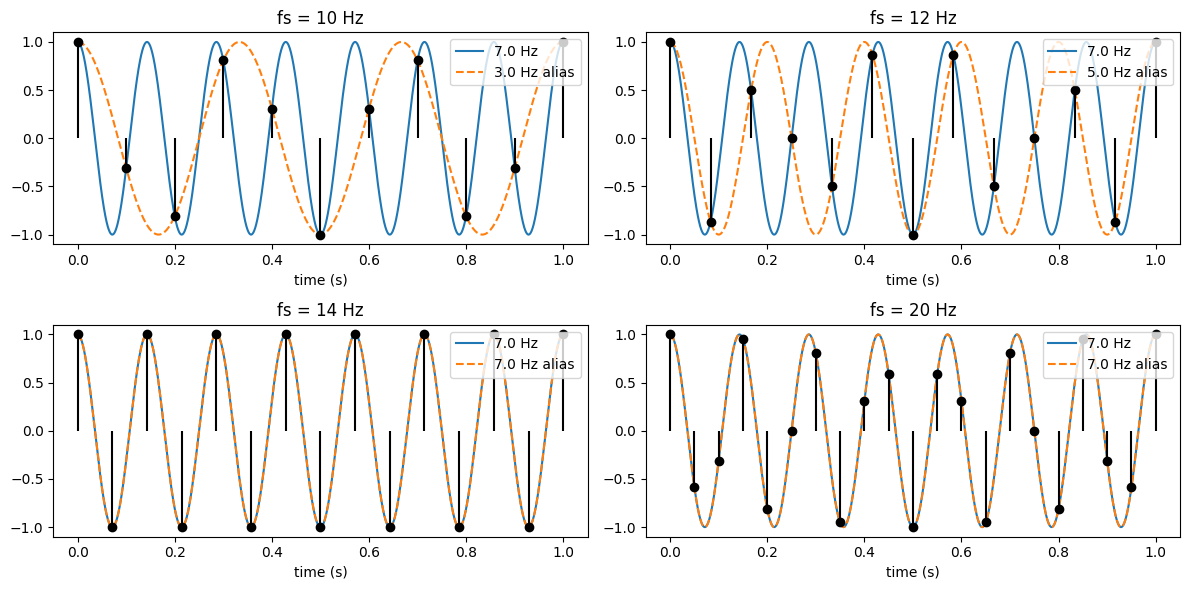

In [ ]:
f0 = 7.0
t = np.linspace(0, 1, 2000)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
print("fs (Hz) | alias (Hz)")
for ax, fs in zip(axes.flat, [10, 12, 14, 20]):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs*round(f0/fs))
    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    ax.set_title(f"fs = {fs} Hz"); ax.set_xlabel("time (s)")
    ax.legend(loc="upper right")
    print(f"{fs:7d} | {f_alias}")
plt.tight_layout(); plt.show()

In [ ]:
!ffmpeg -y -i sound.m4a sound.wav

In [7]:
import os
from IPython.display import Audio, display

fname = "sound.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:                                   # fallback: chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

print("original, fs =", fs, "Hz")
display(Audio(x, rate=fs))

for k in [2, 4, 8]:
    naive  = x[::k]                                  # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")      # low-pass, then drop
    print(f"\nk = {k}, new fs = {fs // k} Hz")
    print("  naive (no filter):")
    display(Audio(naive, rate=fs // k))
    print("  proper (with anti-aliasing filter):")
    display(Audio(proper, rate=fs // k))

original, fs = 48000 Hz



k = 2, new fs = 24000 Hz
  naive (no filter):


  proper (with anti-aliasing filter):



k = 4, new fs = 12000 Hz
  naive (no filter):


  proper (with anti-aliasing filter):



k = 8, new fs = 6000 Hz
  naive (no filter):


  proper (with anti-aliasing filter):


## Task 2.2: Listening observations
For k = 8, the naive version sounded rough and had strange extra noise.
The version made with signal.decimate sounded smoother and cleaner.
This happens because aliasing: without a filter, high frequencies fold back into the low frequencies as false sounds.

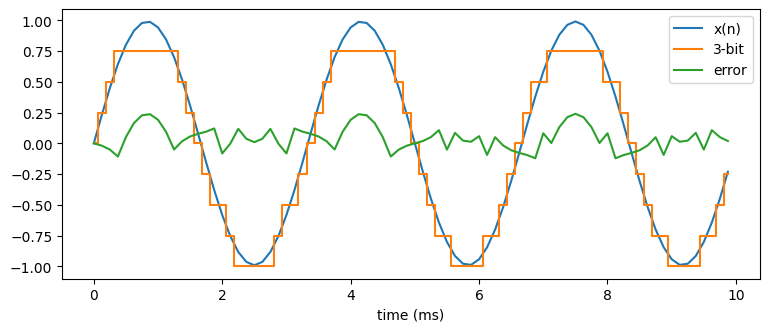

In [8]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.legend(); plt.show()

B =  2 bits | measured =   9.60 dB | theory =  13.80 dB
B =  4 bits | measured =  23.58 dB | theory =  25.84 dB
B =  6 bits | measured =  36.81 dB | theory =  37.88 dB
B =  8 bits | measured =  48.93 dB | theory =  49.92 dB
B = 10 bits | measured =  62.81 dB | theory =  61.96 dB
B = 12 bits | measured =  72.84 dB | theory =  74.00 dB
B = 14 bits | measured =  88.13 dB | theory =  86.04 dB
B = 16 bits | measured =  98.91 dB | theory =  98.08 dB


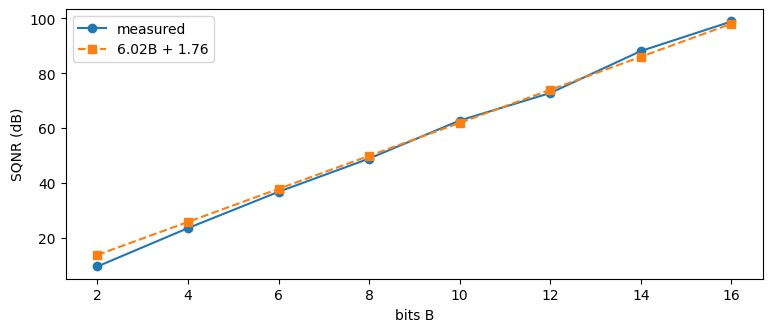

In [9]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]

for B, m in zip(bits, meas):
    print(f"B = {B:2d} bits | measured = {m:6.2f} dB | theory = {6.02*B + 1.76:6.2f} dB")

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.show()

In [10]:
from IPython.display import Audio, display

fsv, xv = wavfile.read("sound.wav")
xv = xv.mean(axis=1) if xv.ndim > 1 else xv.astype(float)
xv = xv / np.max(np.abs(xv))

for B in [4, 8, 12]:
    xq = quantize(xv, B)
    sqnr = 10*np.log10(np.sum(xv**2) / np.sum((xv - xq)**2))
    print(f"B = {B:2d} bits | SQNR = {sqnr:.2f} dB | theory for a full-scale sine = {6.02*B + 1.76:.2f} dB")
    display(Audio(xq, rate=fsv))

B =  4 bits | SQNR = 11.99 dB | theory for a full-scale sine = 25.84 dB


B =  8 bits | SQNR = 35.64 dB | theory for a full-scale sine = 49.92 dB


B = 12 bits | SQNR = 59.72 dB | theory for a full-scale sine = 74.00 dB


## Task 2.1: Alias table (f0 = 7 Hz)
fs = 10 Hz gives alias 3 Hz, fs = 12 Hz gives 5 Hz, fs = 14 Hz gives 7 Hz, fs = 20 Hz gives 7 Hz. These agree with |F - k*fs|.

## Task 2.5: Quantizing my voice
SQNR of my voice: 4 bits = 11.99 dB, 8 bits = 35.64 dB, 12 bits = 59.72 dB.
The 4-bit version sounded rough, noisy and less clear. The 12-bit version sounded almost same as the original one.
The SQNR of speech is about 14 dB lower than the theory for a full-scale sine. Speech is mostly much quieter than its loudest peak and has silent gaps, so its average power is low. The quantization noise stays the same, so the ratio is smaller.

## Analysis Question 1
A sampling rate of 10 Hz can only represent frequencies from 0 to 5 Hz (fs/2). A 7 Hz tone is above 5 Hz, so it folds back and appears at |7 - 10| = 3 Hz. After sampling, the 7 Hz wave and the 3 Hz wave give exactly the same sample values.

## Analysis Question 2
After sampling, the alias at 3 Hz looks exactly like a real 3 Hz tone. There is no way to tell which frequency was in the original signal, so the damage cannot be undone. The low-pass (anti-aliasing) filter must be applied before sampling.

## Analysis Question 3
Each extra bit increases the SQNR by about 6 dB. In my measurement, going from 2 to 16 bits raised the SQNR from 9.60 dB to 98.91 dB, which is about 6.4 dB per bit. My voice recording also gave about 6 dB per bit: from 4 bits (11.99 dB) to 12 bits (59.72 dB) is about 5.97 dB per bit. This agrees with the theory (6.02 dB per bit). The values do not match the formula exactly because my test signal had only 80 samples, so the quantization error was not random.

## Analysis Question 4
The temperature changes by at most 0.1 C per second, so it is a very slow signal. A sampling rate of 1 Hz is enough to follow it. I would choose 10 Hz to be safe, because then the reading changes by at most 0.01 C between samples, which is the same size as the resolution.

## AI-use statement
AI tools used: Claude
Used for: guidance on setting up Colab and running Tasks 2.1 to 2.5
How I verified the output: compared my plots and tables with the expected figures in the lab manual, and checked the alias values against |F - k*fs|
I confirm that I understand and can explain all submitted code.